# **Deep Learning - Lab 5 - Raja Rayyan Ameer - 23-CP-25**

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)


## **Dataset and neural-network implementation**

In [2]:
def make_spiral(n_per=1500, noise=0.30, seed=5, turns=4.0):
    rng = np.random.RandomState(seed)
    Xs, ys = [], []
    for c in (0, 1):
        t = np.sqrt(rng.rand(n_per)) * turns * np.pi
        th = t + c * np.pi + rng.randn(n_per) * noise
        Xs.append(np.c_[t * np.sin(th), t * np.cos(th)])
        ys.append(np.full(n_per, c))
    Xa, ya = np.vstack(Xs), np.concatenate(ys)
    p = rng.permutation(len(ya))
    return Xa[p], ya[p]

Xa, ya = make_spiral()
Xa = (Xa - Xa.mean(axis=0)) / Xa.std(axis=0)
X_train, Y_train = Xa[:2400].T, ya[:2400].reshape(1, -1)
X_test, Y_test = Xa[2400:].T, ya[2400:].reshape(1, -1)

def initialize_parameters(seed=1, layer_dims=(2, 32, 16, 1)):
    rng = np.random.RandomState(seed)
    P = {}
    for l in range(1, len(layer_dims)):
        P[f'W{l}'] = rng.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(2.0 / layer_dims[l-1])
        P[f'b{l}'] = np.zeros((layer_dims[l], 1))
    return P

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def forward(P, X):
    A = X
    cache = []
    L = len(P) // 2
    for l in range(1, L):
        Z = P[f'W{l}'] @ A + P[f'b{l}']
        A_next = np.maximum(0, Z)
        cache.append((A, Z))
        A = A_next
    ZL = P[f'W{L}'] @ A + P[f'b{L}']
    AL = sigmoid(ZL)
    cache.append((A, ZL))
    return AL, cache

def binary_cost(AL, Y):
    m = Y.shape[1]
    eps = 1e-12
    return float(-np.sum(Y*np.log(AL+eps) + (1-Y)*np.log(1-AL+eps)) / m)

def backward(P, Y, AL, cache):
    grads = {}
    m = Y.shape[1]
    L = len(P) // 2
    dZ = AL - Y
    for l in range(L, 0, -1):
        A_prev, Z = cache[l-1]
        grads[f'dW{l}'] = (dZ @ A_prev.T) / m
        grads[f'db{l}'] = np.sum(dZ, axis=1, keepdims=True) / m
        if l > 1:
            dA_prev = P[f'W{l}'].T @ dZ
            Z_prev = cache[l-2][1]
            dZ = dA_prev * (Z_prev > 0)
    return grads

def accuracy(P, X, Y):
    AL, _ = forward(P, X)
    return float(np.mean((AL >= 0.5) == Y))

def random_mini_batches(X, Y, batch_size=64, seed=0):
    rng = np.random.RandomState(seed)
    m = X.shape[1]
    perm = rng.permutation(m)
    Xs, Ys = X[:, perm], Y[:, perm].reshape(1, m)
    batches = []
    n_full = m // batch_size
    for k in range(n_full):
        start, end = k * batch_size, (k + 1) * batch_size
        batches.append((Xs[:, start:end], Ys[:, start:end]))
    if m % batch_size:
        start = n_full * batch_size
        batches.append((Xs[:, start:], Ys[:, start:]))
    return batches


## **Task 1: Mini-batch machinery and batch size**

In [3]:
# Verify divisible and non-divisible batch sizes on 2400 training examples.
for bs in (512, 700):
    batches = random_mini_batches(X_train, Y_train, batch_size=bs, seed=0)
    print(f'Batch size {bs}: {len(batches)} batches; sizes = {[yb.shape[1] for _, yb in batches]}')

print("Shuffle before splitting: it prevents batches from preserving any accidental ordering in the data.")
print("Vary the seed each epoch: this changes the order so the model does not repeatedly see the same batch composition.")


Batch size 512: 5 batches; sizes = [512, 512, 512, 512, 352]
Batch size 700: 4 batches; sizes = [700, 700, 700, 300]
Shuffle before splitting: it prevents batches from preserving any accidental ordering in the data.
Vary the seed each epoch: this changes the order so the model does not repeatedly see the same batch composition.


In [4]:
def train(X, Y, Xv=None, Yv=None, optimizer='gd', lr=0.1, epochs=100,
          batch_size=64, seed=1, beta1=0.9, beta2=0.999, epsilon=1e-8,
          record_batch_costs=False, reset_adam_t_each_epoch=False):
    P = initialize_parameters(seed=seed)
    v = {k: np.zeros_like(val) for k, val in P.items()}
    s = {k: np.zeros_like(val) for k, val in P.items()}
    history = {'cost': [], 'train_acc': [], 'test_acc': [], 'batch_cost': [], 'lr': []}
    t = 0
    start_time = time.perf_counter()
    for epoch in range(epochs):
        if reset_adam_t_each_epoch and optimizer == 'adam':
            t = 0  # Deliberately incorrect option for Task 3 demonstration.
        batches = random_mini_batches(X, Y, batch_size, seed=seed + epoch)
        for Xb, Yb in batches:
            AL, cache = forward(P, Xb)
            grads = backward(P, Yb, AL, cache)
            t += 1
            for l in range(1, len(P)//2 + 1):
                for p in ('W', 'b'):
                    key, g = f'{p}{l}', grads[f'd{p}{l}']
                    if optimizer == 'gd':
                        P[key] -= lr * g
                    elif optimizer == 'momentum':
                        v[key] = beta1*v[key] + (1-beta1)*g
                        P[key] -= lr*v[key]
                    elif optimizer == 'rmsprop':
                        s[key] = beta2*s[key] + (1-beta2)*(g*g)
                        P[key] -= lr*g/(np.sqrt(s[key])+epsilon)
                    elif optimizer == 'adam':
                        v[key] = beta1*v[key] + (1-beta1)*g
                        s[key] = beta2*s[key] + (1-beta2)*(g*g)
                        vhat = v[key] / (1-beta1**t) if beta1 != 0 else v[key]
                        shat = s[key] / (1-beta2**t) if beta2 != 0 else s[key]
                        P[key] -= lr*vhat/(np.sqrt(shat)+epsilon)
                    else:
                        raise ValueError("optimizer must be gd, momentum, rmsprop, or adam")
            if record_batch_costs:
                Ab, _ = forward(P, Xb)
                history['batch_cost'].append(binary_cost(Ab, Yb))
        AL, _ = forward(P, X)
        history['cost'].append(binary_cost(AL, Y))
        history['train_acc'].append(accuracy(P, X, Y))
        if Xv is not None and Yv is not None:
            history['test_acc'].append(accuracy(P, Xv, Yv))
        history['lr'].append(lr)
    history['time'] = time.perf_counter() - start_time
    history['updates'] = epochs * int(np.ceil(X.shape[1]/batch_size))
    history['params'] = P
    return history

def epochs_to_target(costs, target=0.35):
    hits = np.where(np.asarray(costs) < target)[0]
    return int(hits[0] + 1) if len(hits) else None

batch_results = {}
for bs in (2400, 512, 128, 32, 8):
    h = train(X_train, Y_train, X_test, Y_test, optimizer='gd', lr=0.3,
              epochs=80, batch_size=bs, seed=1, record_batch_costs=bs in (2400,128,8))
    batch_results[bs] = h
    print(f"batch={bs:4d} updates={h['updates']:5d} epochs_to_cost<0.35={epochs_to_target(h['cost'])} "
          f"final_cost={h['cost'][-1]:.4f} train_acc={h['train_acc'][-1]:.3f} "
          f"test_acc={h['test_acc'][-1]:.3f} time={h['time']:.2f}s")


batch=2400 updates=   80 epochs_to_cost<0.35=None final_cost=0.6262 train_acc=0.649 test_acc=0.608 time=0.43s
batch= 512 updates=  400 epochs_to_cost<0.35=None final_cost=0.6031 train_acc=0.551 test_acc=0.535 time=0.59s
batch= 128 updates= 1520 epochs_to_cost<0.35=44 final_cost=0.0496 train_acc=0.987 test_acc=0.982 time=1.00s
batch=  32 updates= 6000 epochs_to_cost<0.35=14 final_cost=0.0053 train_acc=0.999 test_acc=0.998 time=1.44s
batch=   8 updates=24000 epochs_to_cost<0.35=5 final_cost=0.0330 train_acc=0.988 test_acc=0.980 time=7.12s


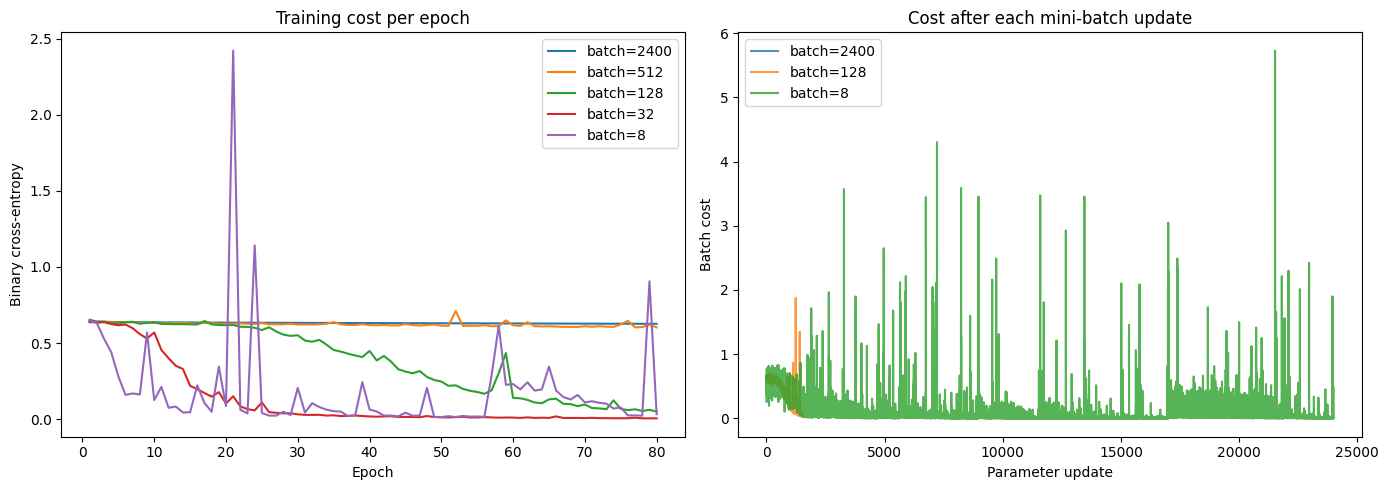

Observation guide: smaller batches usually produce noisier per-update costs and more updates per epoch.
Use the printed measurements above to compare target epochs, wall-clock time, and final accuracy; timing depends on the computer.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for bs, h in batch_results.items():
    axes[0].plot(np.arange(1, len(h['cost'])+1), h['cost'], label=f'batch={bs}')
axes[0].set(title='Training cost per epoch', xlabel='Epoch', ylabel='Binary cross-entropy')
axes[0].legend()
for bs in (2400, 128, 8):
    axes[1].plot(batch_results[bs]['batch_cost'], label=f'batch={bs}', alpha=0.8)
axes[1].set(title='Cost after each mini-batch update', xlabel='Parameter update', ylabel='Batch cost')
axes[1].legend()
plt.tight_layout()
plt.show()

print("Observation guide: smaller batches usually produce noisier per-update costs and more updates per epoch.")
print("Use the printed measurements above to compare target epochs, wall-clock time, and final accuracy; timing depends on the computer.")


## **Task 2: Exponentially weighted averages and bias correction**

beta=0.5: approximate averaging window = 2 steps
beta=0.9: approximate averaging window = 10 steps
beta=0.98: approximate averaging window = 50 steps


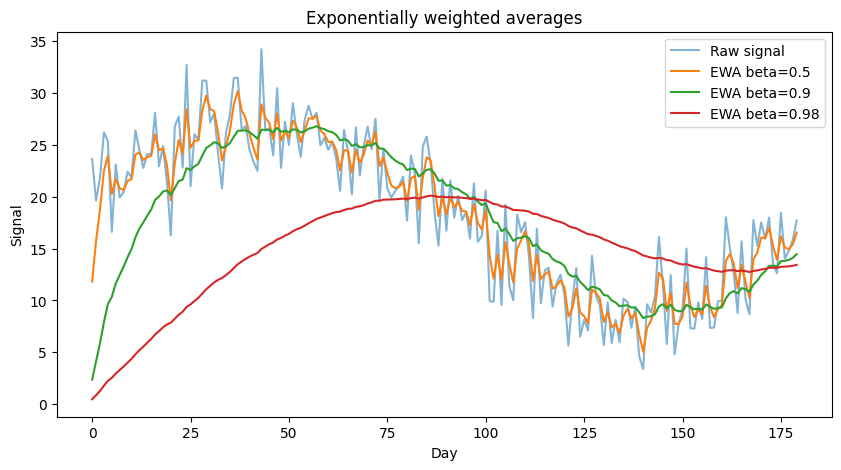

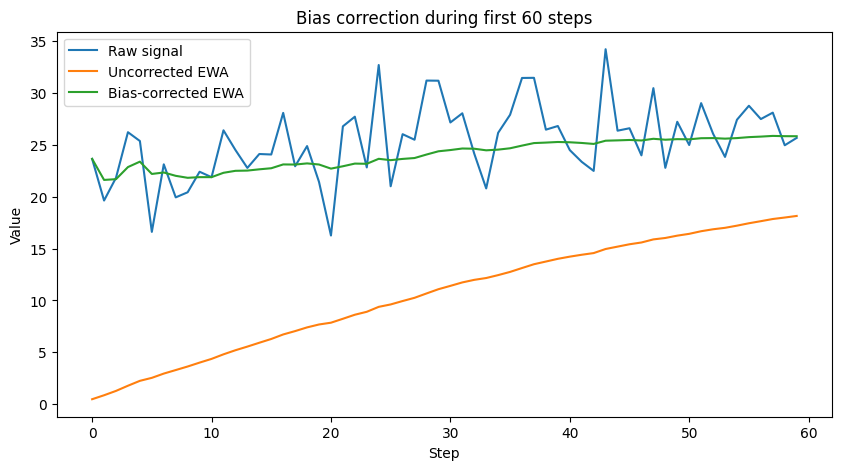

First five raw values:         [23.64497 19.6295  21.82953 26.21614 25.36792]
First five uncorrected values: [0.4729  0.85603 1.2755  1.77431 2.24619]
First five corrected values:   [23.64497 21.61695 21.68925 22.85549 23.37848]
At t=1, uncorrected v1=(1-beta)*x1=0.47290; corrected v1=v1/(1-beta)=23.64497.


In [6]:
np.random.seed(0)
days = np.arange(180)
signal = 18 + 10*np.sin(2*np.pi*days/180) + np.random.randn(180)*3.2

def ewa(x, beta, correct=False):
    v = 0.0
    out = []
    for i, xi in enumerate(x):
        v = beta*v + (1-beta)*xi
        out.append(v/(1-beta**(i+1)) if correct else v)
    return np.asarray(out)

plt.figure(figsize=(10,5))
plt.plot(days, signal, label='Raw signal', alpha=0.55)
for beta in (0.5, 0.9, 0.98):
    plt.plot(days, ewa(signal, beta), label=f'EWA beta={beta}')
    print(f'beta={beta}: approximate averaging window = {1/(1-beta):.0f} steps')
plt.xlabel('Day'); plt.ylabel('Signal'); plt.title('Exponentially weighted averages')
plt.legend(); plt.show()

beta = 0.98
uncorrected, corrected = ewa(signal, beta), ewa(signal, beta, correct=True)
plt.figure(figsize=(10,5))
plt.plot(days[:60], signal[:60], label='Raw signal')
plt.plot(days[:60], uncorrected[:60], label='Uncorrected EWA')
plt.plot(days[:60], corrected[:60], label='Bias-corrected EWA')
plt.xlabel('Step'); plt.ylabel('Value'); plt.title('Bias correction during first 60 steps')
plt.legend(); plt.show()
print("First five raw values:        ", signal[:5])
print("First five uncorrected values:", uncorrected[:5])
print("First five corrected values:  ", corrected[:5])
print(f"At t=1, uncorrected v1=(1-beta)*x1={((1-beta)*signal[0]):.5f}; corrected v1=v1/(1-beta)={corrected[0]:.5f}.")


## **Task 3: Momentum, RMSProp and Adam**

gd       lr=0.3 final_cost=0.00695 train_acc=0.998 test_acc=0.998
momentum lr=0.3 final_cost=0.00939 train_acc=0.996 test_acc=0.997
rmsprop  lr=0.005 final_cost=0.00192 train_acc=1.000 test_acc=0.998
adam     lr=0.01 final_cost=0.00060 train_acc=1.000 test_acc=0.998


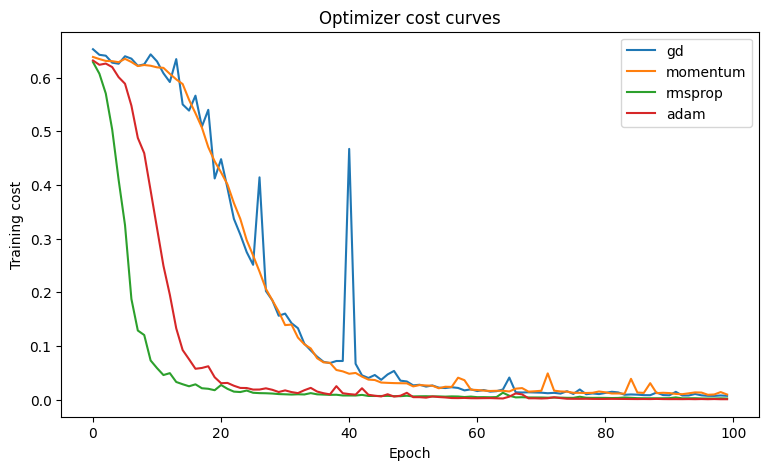

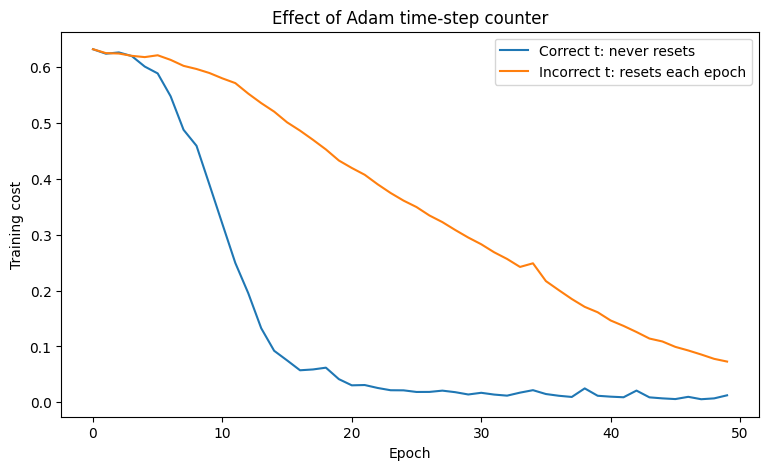

beta1=0 removes the averaged-gradient/momentum term; with beta2 retained, this is a bias-corrected RMSProp-like update.
beta2=0 makes the squared-gradient accumulator equal the current squared gradient; after bias correction, the denominator is based on the current gradient magnitude.
Momentum reduces oscillation in steep directions. RMSProp adapts each parameter's step size when gradient magnitudes differ.


In [7]:
# Compare all four optimizers using a common baseline setup.
task3_results = {}
for opt, lr in [('gd',0.3), ('momentum',0.3), ('rmsprop',0.005), ('adam',0.01)]:
    h = train(X_train, Y_train, X_test, Y_test, optimizer=opt, lr=lr,
              epochs=100, batch_size=64, seed=1)
    task3_results[opt] = h
    print(f"{opt:8s} lr={lr:g} final_cost={h['cost'][-1]:.5f} "
          f"train_acc={h['train_acc'][-1]:.3f} test_acc={h['test_acc'][-1]:.3f}")

plt.figure(figsize=(9,5))
for opt, h in task3_results.items():
    plt.plot(h['cost'], label=opt)
plt.xlabel('Epoch'); plt.ylabel('Training cost'); plt.title('Optimizer cost curves')
plt.legend(); plt.show()

# Incorrect Adam counter reset each epoch vs correct counter.
adam_correct = train(X_train, Y_train, X_test, Y_test, optimizer='adam', lr=0.01,
                     epochs=50, batch_size=64, seed=1)
adam_reset = train(X_train, Y_train, X_test, Y_test, optimizer='adam', lr=0.01,
                   epochs=50, batch_size=64, seed=1, reset_adam_t_each_epoch=True)
plt.figure(figsize=(9,5))
plt.plot(adam_correct['cost'], label='Correct t: never resets')
plt.plot(adam_reset['cost'], label='Incorrect t: resets each epoch')
plt.xlabel('Epoch'); plt.ylabel('Training cost'); plt.title('Effect of Adam time-step counter')
plt.legend(); plt.show()
print("beta1=0 removes the averaged-gradient/momentum term; with beta2 retained, this is a bias-corrected RMSProp-like update.")
print("beta2=0 makes the squared-gradient accumulator equal the current squared gradient; after bias correction, the denominator is based on the current gradient magnitude.")
print("Momentum reduces oscillation in steep directions. RMSProp adapts each parameter's step size when gradient magnitudes differ.")


##**Task 4: Fair optimizer comparison**

gd       shared_lr=0.1 mean_final_cost=0.21098 mean_test_acc=0.863
momentum shared_lr=0.1 mean_final_cost=0.09515 mean_test_acc=0.967
rmsprop  shared_lr=0.1 mean_final_cost=0.45907 mean_test_acc=0.694
adam     shared_lr=0.1 mean_final_cost=0.18562 mean_test_acc=0.877


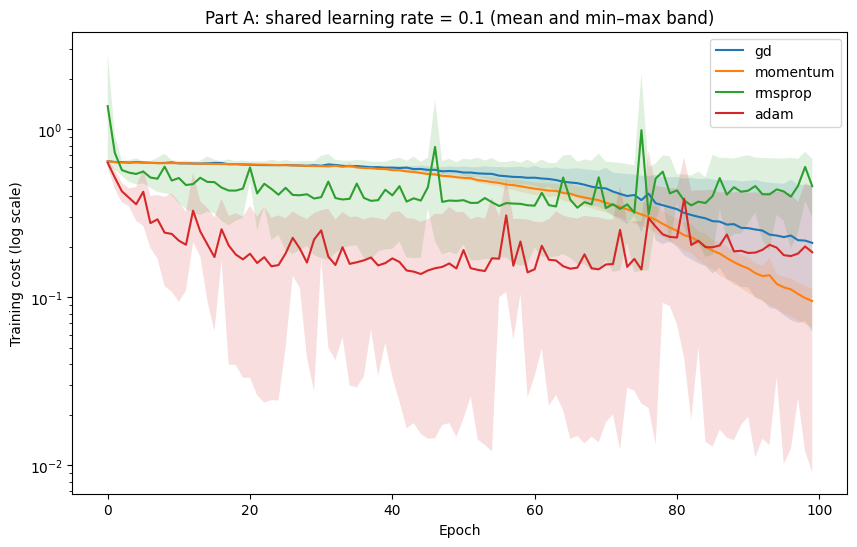


 gd
{'lr': 0.03, 'epochs_to_target': None, 'final_cost': 0.5994187082641236, 'test_acc': 0.5216666666666666}
{'lr': 0.1, 'epochs_to_target': 77, 'final_cost': 0.10788446032628267, 'test_acc': 0.9566666666666667}
{'lr': 0.3, 'epochs_to_target': 23, 'final_cost': 0.006950513185337189, 'test_acc': 0.9983333333333333}
{'lr': 0.5, 'epochs_to_target': 17, 'final_cost': 0.005129442061066163, 'test_acc': 0.9983333333333333}
{'lr': 1.0, 'epochs_to_target': 11, 'final_cost': 0.10351659640495654, 'test_acc': 0.9533333333333334}

 momentum
{'lr': 0.1, 'epochs_to_target': 78, 'final_cost': 0.1066758325246675, 'test_acc': 0.9566666666666667}
{'lr': 0.3, 'epochs_to_target': 24, 'final_cost': 0.009385501851380556, 'test_acc': 0.9966666666666667}
{'lr': 0.5, 'epochs_to_target': 15, 'final_cost': 0.006805033564952856, 'test_acc': 0.9966666666666667}
{'lr': 1.0, 'epochs_to_target': 9, 'final_cost': 0.0029699899748985683, 'test_acc': 1.0}
{'lr': 2.0, 'epochs_to_target': 7, 'final_cost': 0.055797078497985

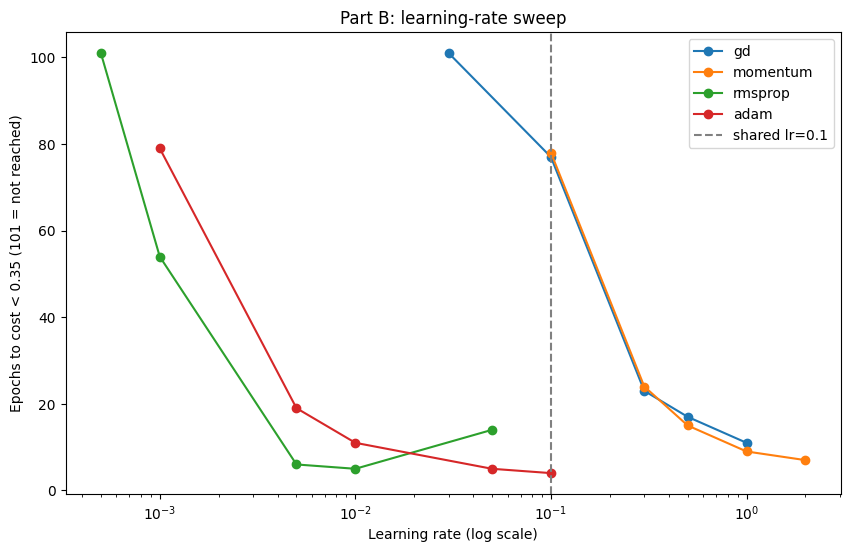

Selected learning rates: {'gd': 0.5, 'momentum': 1.0, 'rmsprop': 0.01, 'adam': 0.05}
gd       lr=0.5; epochs_to_target=[17, 21, 21]; mean_final_cost=0.00544; test_acc_mean=0.998; test_acc_std=0.000
momentum lr=1; epochs_to_target=[9, 11, 11]; mean_final_cost=0.00474; test_acc_mean=0.998; test_acc_std=0.002
rmsprop  lr=0.01; epochs_to_target=[5, 6, 8]; mean_final_cost=0.00486; test_acc_mean=0.998; test_acc_std=0.000
adam     lr=0.05; epochs_to_target=[5, 4, 7]; mean_final_cost=0.00725; test_acc_mean=0.996; test_acc_std=0.004
Interpretation: a shared learning rate is not fair because each optimizer scales and smooths gradients differently.
Use the per-optimizer sweep and fair-comparison measurements above in the report; report both the learning rates and seed variability.


In [8]:
# Same learning rate for all optimizers (intentionally naive comparison).
naive_lrs = {'gd':0.1, 'momentum':0.1, 'rmsprop':0.1, 'adam':0.1}
naive = {}
for opt, lr in naive_lrs.items():
    runs = [train(X_train,Y_train,X_test,Y_test,optimizer=opt,lr=lr,epochs=100,batch_size=64,seed=s)
            for s in (1,2,3)]
    naive[opt] = runs
    print(f"{opt:8s} shared_lr={lr} mean_final_cost={np.mean([r['cost'][-1] for r in runs]):.5f} "
          f"mean_test_acc={np.mean([r['test_acc'][-1] for r in runs]):.3f}")

plt.figure(figsize=(10,6))
for opt, runs in naive.items():
    curves = np.array([r['cost'] for r in runs])
    mean, low, high = curves.mean(axis=0), curves.min(axis=0), curves.max(axis=0)
    plt.plot(mean, label=opt)
    plt.fill_between(np.arange(len(mean)), low, high, alpha=0.15)
plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('Training cost (log scale)')
plt.title('Part A: shared learning rate = 0.1 (mean and min–max band)')
plt.legend(); plt.show()

lr_grid = {
    'gd':[0.03,0.1,0.3,0.5,1.0],
    'momentum':[0.1,0.3,0.5,1.0,2.0],
    'rmsprop':[0.0005,0.001,0.005,0.01,0.05],
    'adam':[0.001,0.005,0.01,0.05,0.1]
}
sweep = {}
for opt, rates in lr_grid.items():
    sweep[opt] = []
    for lr in rates:
        h = train(X_train,Y_train,X_test,Y_test,optimizer=opt,lr=lr,epochs=100,batch_size=64,seed=1)
        sweep[opt].append({'lr':lr, 'epochs_to_target':epochs_to_target(h['cost']),
                           'final_cost':h['cost'][-1], 'test_acc':h['test_acc'][-1]})
    print('\n', opt)
    for row in sweep[opt]:
        print(row)

plt.figure(figsize=(10,6))
for opt, rows in sweep.items():
    xs = [r['lr'] for r in rows]
    ys = [r['epochs_to_target'] if r['epochs_to_target'] is not None else 101 for r in rows]
    plt.plot(xs, ys, marker='o', label=opt)
plt.xscale('log'); plt.axvline(0.1, color='gray', linestyle='--', label='shared lr=0.1')
plt.xlabel('Learning rate (log scale)'); plt.ylabel('Epochs to cost < 0.35 (101 = not reached)')
plt.title('Part B: learning-rate sweep'); plt.legend(); plt.show()

chosen = {}
for opt, rows in sweep.items():
    valid = [r for r in rows if r['final_cost'] < 0.02]
    if valid:
        chosen[opt] = min(valid, key=lambda r: r['epochs_to_target'] if r['epochs_to_target'] is not None else 10**9)['lr']
    else:
        # Explicit fallback if no grid value satisfies the manual's final-cost condition.
        chosen[opt] = min(rows, key=lambda r: r['final_cost'])['lr']
        print(f"NOTE: {opt} had no sweep value with final cost < 0.02; fallback is lowest final cost.")
print("Selected learning rates:", chosen)

fair = {}
for opt, lr in chosen.items():
    runs = [train(X_train,Y_train,X_test,Y_test,optimizer=opt,lr=lr,epochs=100,batch_size=64,seed=s)
            for s in (1,2,3)]
    fair[opt] = runs
    print(f"{opt:8s} lr={lr:g}; epochs_to_target={[epochs_to_target(r['cost']) for r in runs]}; "
          f"mean_final_cost={np.mean([r['cost'][-1] for r in runs]):.5f}; "
          f"test_acc_mean={np.mean([r['test_acc'][-1] for r in runs]):.3f}; "
          f"test_acc_std={np.std([r['test_acc'][-1] for r in runs]):.3f}")

print("Interpretation: a shared learning rate is not fair because each optimizer scales and smooths gradients differently.")
print("Use the per-optimizer sweep and fair-comparison measurements above in the report; report both the learning rates and seed variability.")


##**Task 5: Learning-rate schedules**

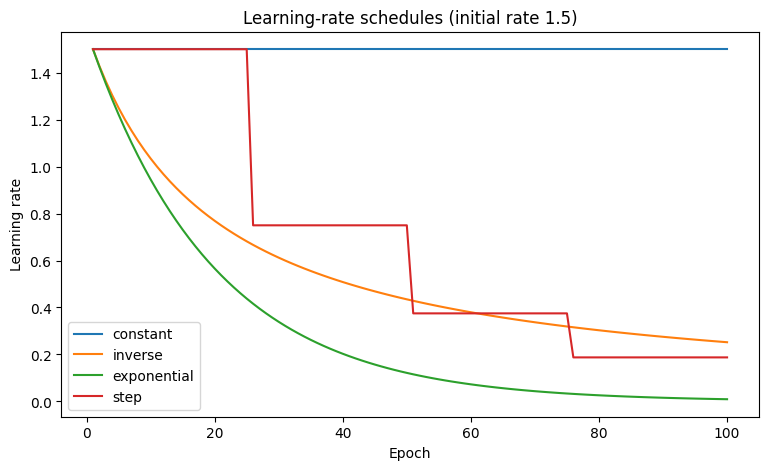

constant    target_epoch=7 final_cost=0.03115 train_acc=0.992 test_acc=0.988 final_lr=1.50000 last20_cost_std=0.00668
inverse     target_epoch=8 final_cost=0.00538 train_acc=0.998 test_acc=0.998 final_lr=0.25210 last20_cost_std=0.00030
exponential target_epoch=8 final_cost=0.01226 train_acc=0.995 test_acc=0.997 final_lr=0.00935 last20_cost_std=0.00006
step        target_epoch=7 final_cost=0.01083 train_acc=0.996 test_acc=0.997 final_lr=0.18750 last20_cost_std=0.00040


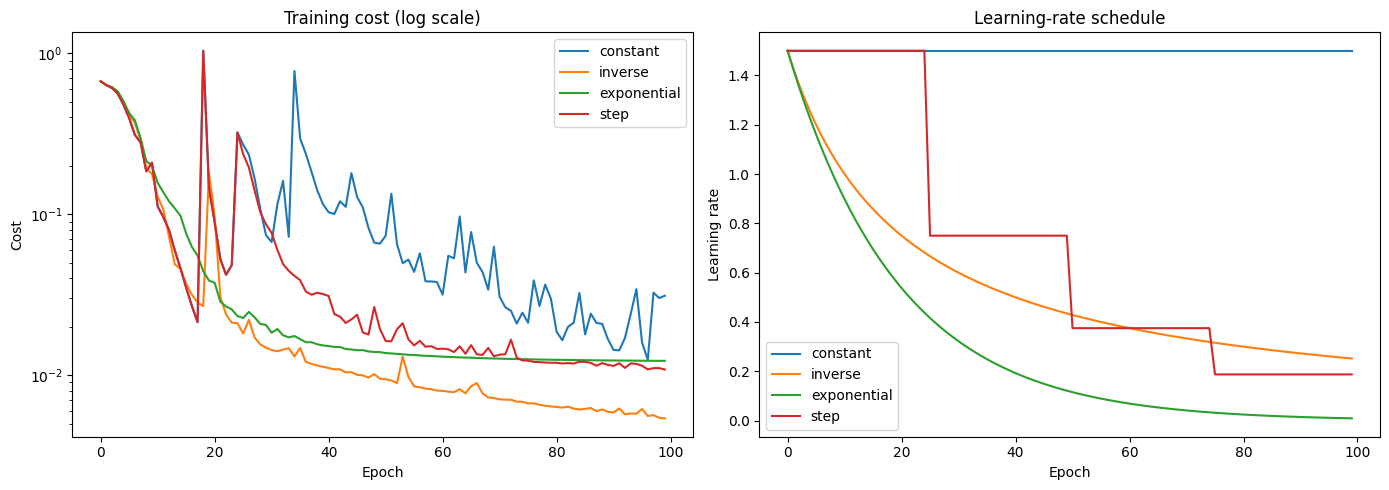

Condition: decay helps when the initial rate makes fast progress but a fixed rate causes late-stage oscillation or stalls above a good minimum.
If the initial learning rate is already small/stable and late-stage oscillation is not a problem, decay may provide little benefit.
initial=0.5 constant    final_cost=0.00681 last20_std=0.00814
initial=0.5 inverse     final_cost=0.01619 last20_std=0.00124
initial=0.5 exponential final_cost=0.09560 last20_std=0.00113
initial=0.5 step        final_cost=0.01282 last20_std=0.00030


In [9]:
def learning_rate_schedule(epoch, alpha0=1.5, schedule='constant', decay=0.05):
    # epoch is zero-based.
    if schedule == 'constant':
        return alpha0
    if schedule == 'inverse':
        return alpha0 / (1 + decay*epoch)
    if schedule == 'exponential':
        return alpha0 * (0.95**epoch)
    if schedule == 'step':
        return alpha0 * (0.5**(epoch//25))
    raise ValueError("Unknown schedule")

epochs_axis = np.arange(100)
plt.figure(figsize=(9,5))
for sch in ('constant','inverse','exponential','step'):
    plt.plot(epochs_axis+1, [learning_rate_schedule(e,1.5,sch) for e in epochs_axis], label=sch)
plt.xlabel('Epoch'); plt.ylabel('Learning rate'); plt.title('Learning-rate schedules (initial rate 1.5)')
plt.legend(); plt.show()

def train_momentum_schedule(alpha0, schedule, seed=1, epochs=100):
    P = initialize_parameters(seed=seed)
    v = {k: np.zeros_like(val) for k,val in P.items()}
    costs, train_accs, test_accs, lrs = [], [], [], []
    for epoch in range(epochs):
        lr_now = learning_rate_schedule(epoch, alpha0, schedule)
        lrs.append(lr_now)
        for Xb, Yb in random_mini_batches(X_train,Y_train,64,seed+epoch):
            AL, cache = forward(P,Xb)
            grads = backward(P,Yb,AL,cache)
            for l in range(1,len(P)//2+1):
                for p in ('W','b'):
                    key=f'{p}{l}'
                    v[key]=0.9*v[key]+0.1*grads[f'd{p}{l}']
                    P[key]-=lr_now*v[key]
        AL,_=forward(P,X_train); costs.append(binary_cost(AL,Y_train))
        train_accs.append(accuracy(P,X_train,Y_train)); test_accs.append(accuracy(P,X_test,Y_test))
    return {'cost':costs,'train_acc':train_accs,'test_acc':test_accs,'lr':lrs,'params':P}

schedule_results = {}
for sch in ('constant','inverse','exponential','step'):
    h = train_momentum_schedule(1.5,sch,seed=1)
    schedule_results[sch]=h
    print(f"{sch:11s} target_epoch={epochs_to_target(h['cost'])} final_cost={h['cost'][-1]:.5f} "
          f"train_acc={h['train_acc'][-1]:.3f} test_acc={h['test_acc'][-1]:.3f} "
          f"final_lr={h['lr'][-1]:.5f} last20_cost_std={np.std(h['cost'][-20:]):.5f}")

fig, axes = plt.subplots(1,2,figsize=(14,5))
for sch,h in schedule_results.items():
    axes[0].plot(h['cost'],label=sch)
    axes[1].plot(h['lr'],label=sch)
axes[0].set_yscale('log'); axes[0].set(title='Training cost (log scale)',xlabel='Epoch',ylabel='Cost')
axes[1].set(title='Learning-rate schedule',xlabel='Epoch',ylabel='Learning rate')
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()

print("Condition: decay helps when the initial rate makes fast progress but a fixed rate causes late-stage oscillation or stalls above a good minimum.")
print("If the initial learning rate is already small/stable and late-stage oscillation is not a problem, decay may provide little benefit.")
schedule_low = {sch:train_momentum_schedule(0.5,sch,seed=1) for sch in ('constant','inverse','exponential','step')}
for sch,h in schedule_low.items():
    print(f"initial=0.5 {sch:11s} final_cost={h['cost'][-1]:.5f} last20_std={np.std(h['cost'][-20:]):.5f}")


##**Task 6: Trajectories on a ravine and a saddle**

Curvatures (Hessian eigenvalues): (0.02, 10.0)
Condition number: 500.0
GD stability limit: lr < 0.2
GD lr=0.05: final f=0.59997269604644; divergence_step=None
GD lr=0.10: final f=0.44427042683129364; divergence_step=None
GD lr=0.18: final f=0.2745368701546226; divergence_step=None
GD lr=0.20: final f=20.24338092983414; divergence_step=None
GD lr=0.21: final f=52340219923767.3; divergence_step=None
GD lr=0.25: final f=1.3440261306029104e+54; divergence_step=None
gd       lr=0.18: final f=0.2745368701546226
momentum lr=0.2: final f=0.2515323414585932
rmsprop  lr=0.01: final f=0.08965249412865169
adam     lr=0.1: final f=0.0013108457483815338


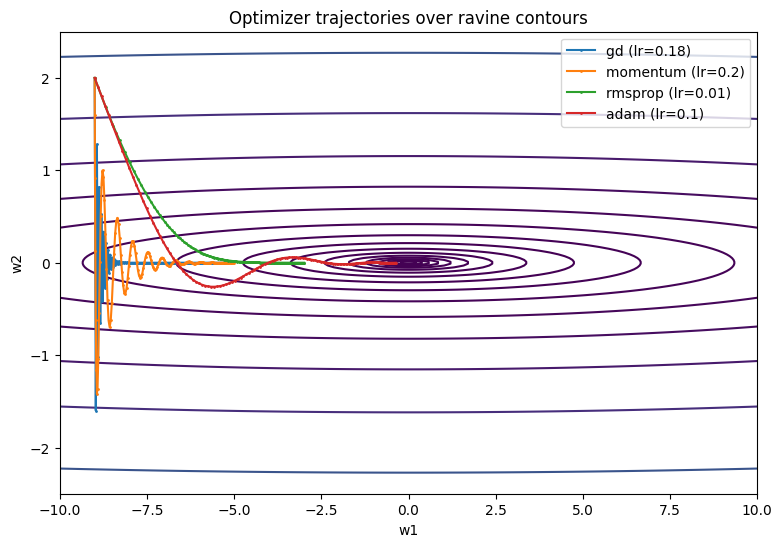

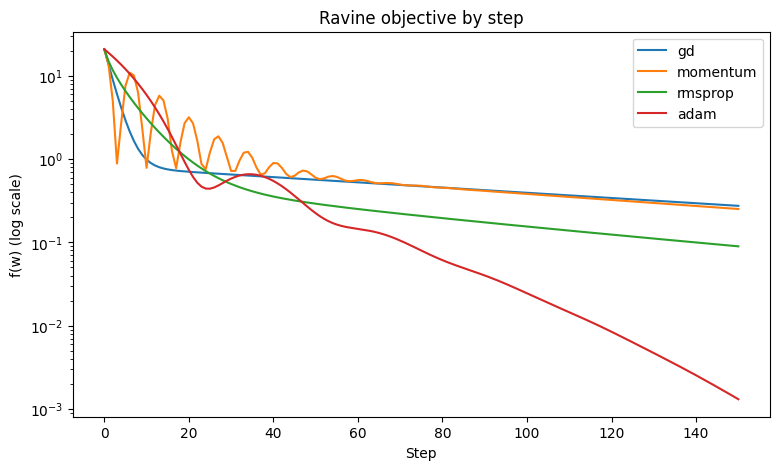

GD has to use a small enough step for the steep direction, so progress along the shallow direction is slow.
Momentum averages gradients, damping zig-zag motion across the ravine while accumulating progress along its length.
gd       lr=0.1: first step |w2|>0.1 = 26; final w=[-0.00423  0.11448]
momentum lr=0.1: first step |w2|>0.1 = 49; final w=[-0.11086  0.1024 ]
rmsprop  lr=0.01: first step |w2|>0.1 = 1; final w=[-1.08377  0.31718]
adam     lr=0.01: first step |w2|>0.1 = 11; final w=[-1.29032  0.10454]


In [10]:
# Ravine surface f(w) = A*w1^2 + B*w2^2
A, B = 0.01, 5.0
def f_ravine(w):
    return A*w[0]**2 + B*w[1]**2
def grad_ravine(w):
    return np.array([2*A*w[0], 2*B*w[1]])

curvatures = (2*A, 2*B)
condition_number = max(curvatures)/min(curvatures)
# For quadratic Hessian eigenvalue lambda_max, GD stable for 0 < lr < 2/lambda_max.
lr_stability = 2/max(curvatures)
print("Curvatures (Hessian eigenvalues):", curvatures)
print("Condition number:", condition_number)
print("GD stability limit: lr <", lr_stability)

def run_surface(opt, lr, steps=150, start=(-9.0,2.0), beta=0.9, beta2=0.999):
    w=np.array(start,dtype=float)
    v=np.zeros(2); s=np.zeros(2); path=[w.copy()]
    for t in range(1,steps+1):
        g=grad_ravine(w)
        if opt=='gd':
            w-=lr*g
        elif opt=='momentum':
            v=beta*v+(1-beta)*g
            w-=lr*v
        elif opt=='rmsprop':
            s=beta2*s+(1-beta2)*g*g
            w-=lr*g/(np.sqrt(s)+1e-8)
        elif opt=='adam':
            v=beta*v+(1-beta)*g; s=beta2*s+(1-beta2)*g*g
            vh=v/(1-beta**t); sh=s/(1-beta2**t)
            w-=lr*vh/(np.sqrt(sh)+1e-8)
        path.append(w.copy())
        if not np.all(np.isfinite(w)) or np.linalg.norm(w)>1e100:
            return np.array(path), None, t
    return np.array(path), f_ravine(w), None

gd_rates=[0.05,0.10,0.18,0.20,0.21,0.25]
for lr in gd_rates:
    path,val,div=run_surface('gd',lr)
    print(f"GD lr={lr:.2f}: final f={val if val is not None else 'diverged'}; divergence_step={div}")

# Use stable, illustrative rates for path visualization; adaptive methods have different useful scales.
surface_rates={'gd':0.18,'momentum':0.2,'rmsprop':0.01,'adam':0.1}
surface_paths={}
for opt,lr in surface_rates.items():
    path,val,div=run_surface(opt,lr)
    surface_paths[opt]=(path,val)
    print(f"{opt:8s} lr={lr:g}: final f={val}")

w1=np.linspace(-10,10,250); w2=np.linspace(-2.5,2.5,250)
G1,G2=np.meshgrid(w1,w2)
Z=A*G1**2+B*G2**2
plt.figure(figsize=(9,6))
plt.contour(G1,G2,Z,levels=np.logspace(-3,2,18))
for opt,(path,val) in surface_paths.items():
    plt.plot(path[:,0],path[:,1],marker='.',markersize=2,label=f'{opt} (lr={surface_rates[opt]})')
plt.xlim(-10,10); plt.ylim(-2.5,2.5); plt.xlabel('w1'); plt.ylabel('w2')
plt.title('Optimizer trajectories over ravine contours'); plt.legend(); plt.show()

plt.figure(figsize=(9,5))
for opt,(path,val) in surface_paths.items():
    vals=[f_ravine(w) for w in path]
    plt.plot(vals,label=opt)
plt.yscale('log'); plt.xlabel('Step'); plt.ylabel('f(w) (log scale)')
plt.title('Ravine objective by step'); plt.legend(); plt.show()

print("GD has to use a small enough step for the steep direction, so progress along the shallow direction is slow.")
print("Momentum averages gradients, damping zig-zag motion across the ravine while accumulating progress along its length.")

# Saddle: f(w1,w2)=w1^2-w2^2; gradient = [2*w1, -2*w2]
def grad_saddle(w):
    return np.array([2*w[0], -2*w[1]])

def saddle_escape_step(opt, lr, steps=200, start=(-1.4,0.001), beta=0.9, beta2=0.999):
    w=np.array(start,dtype=float); v=np.zeros(2); s=np.zeros(2)
    for t in range(1,steps+1):
        g=grad_saddle(w)
        if opt=='gd':
            w-=lr*g
        elif opt=='momentum':
            v=beta*v+(1-beta)*g; w-=lr*v
        elif opt=='rmsprop':
            s=beta2*s+(1-beta2)*g*g; w-=lr*g/(np.sqrt(s)+1e-8)
        elif opt=='adam':
            v=beta*v+(1-beta)*g; s=beta2*s+(1-beta2)*g*g
            w-=lr*(v/(1-beta**t))/(np.sqrt(s/(1-beta2**t))+1e-8)
        if abs(w[1])>0.1:
            return t, w.copy()
    return None, w

saddle_rates={'gd':0.1,'momentum':0.1,'rmsprop':0.01,'adam':0.01}
for opt,lr in saddle_rates.items():
    step,w=saddle_escape_step(opt,lr)
    print(f"{opt:8s} lr={lr:g}: first step |w2|>0.1 = {step}; final w={w}")
